# Notebook 02 - Pipeline de modelado y evaluación clínica

## Objetivos
- Construir un pipeline reproducible para predecir cáncer de pulmón con variables SNOMED, RxNorm y LOINC.
- Preprocesar cada dominio clínico con transformaciones específicas para variables categóricas y numéricas.
- Entrenar y comparar modelos con validación y selección basada en métricas.
- Registrar experimentos, métricas y artefactos en MLflow para trazabilidad.
- Analizar variables relevantes y patrones de la cohorte para interpretar resultados.

## Resumen de secciones y celdas

| Sección | Objetivo | Celdas (aprox.) |
|---|---|---|
| Carga de librerías y datos | Inicializar entorno, cargar datasets y preparar partición train/test | 2-8 |
| Preprocesamiento SNOMED | Definir codificación de diagnósticos/procedimientos y variables demográficas | 9-13 |
| Preprocesamiento medicamentos | Definir transformación base para variables de RxNorm | 14-17 |
| Preprocesamiento laboratorio | Analizar tipos, agrupar categorías y construir transformador de laboratorio | 18-30 |
| Modelado inicial de laboratorio | Ejecutar validación anidada con regresión logística | 31 |
| Tuning y evaluación multmodelo | Ajustar varios modelos y comparar rendimiento en test | 32-39 |
| Tracking y artefactos MLflow | Registrar parámetros, métricas, modelos y gráficas PR/ROC | 40-46 |
| Pipeline global multimodal | Integrar SNOMED + medicamentos + laboratorio en un único pipeline XGBoost | 47-53 |
| Importancia de variables y EDA | Extraer variables relevantes y explorar patrones de cohorte | 54-75 |

## Notas de organización
- El notebook está estructurado de lo general a lo específico: datos, preprocesamiento, modelado, evaluación y análisis.
- Se han reducido comentarios internos en código para mejorar legibilidad sin perder trazabilidad metodológica.

In [1]:
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from funciones import obtener_info_valores_unicos, extraccion_columnas


from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn import set_config
from sklearn.metrics import classification_report

from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show


# Definición de los datos

In [2]:
load_dotenv(find_dotenv())

PROJECT_ROOT = Path(find_dotenv()).parent.resolve()
print(f"PROJECT_ROOT set to: {PROJECT_ROOT}")
DATA_DIR = PROJECT_ROOT / 'data'

PROJECT_ROOT set to: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025


In [ ]:
datos_original = pd.read_csv(DATA_DIR / 'synthea_30k.csv', low_memory=False)

In [4]:
datos_SNOMED = pd.read_csv(DATA_DIR / 'synthea_snomed.csv', low_memory=False)
datos_MEDICAMENTOS= pd.read_csv(DATA_DIR / 'synthea_rxnorm.csv',low_memory=False)
datos_LABORATORIO=  pd.read_csv(DATA_DIR / 'synthea_loinc.csv',low_memory=False)

datos_SNOMED.set_index('ptnum', inplace=True)
datos_MEDICAMENTOS.set_index('ptnum', inplace=True)
datos_LABORATORIO.set_index('ptnum', inplace=True)


datos_totales = pd.concat([datos_SNOMED,datos_LABORATORIO, datos_MEDICAMENTOS], axis=1)

In [5]:
X=datos_totales.drop(columns="label")
y=datos_totales["label"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.1, random_state=625, stratify=y)

X_train_lab = X_train[datos_LABORATORIO.drop(columns=['label']).columns]
X_test_lab = X_test[datos_LABORATORIO.drop(columns=['label']).columns]

# Datos SNOMED

In [7]:
obtener_info_valores_unicos(datos_SNOMED)

,Indices_iloc,Soporte
0,[218],"[hawaiian, asian, white, other, native, black]"
1,[219],"[m, s]"
2,[220],"[hispanic, nonhispanic]"
3,[221],"[m, f]"
4,[222],[massachusetts]
5,[223],"[gt70, 50t70, 30t50]"


In [8]:
col_OH=datos_SNOMED.columns[[218]]
col_OR=datos_SNOMED.columns[[219,220,221,222]]
col_edad=datos_SNOMED.columns[[223]]


## Pipeline para diagnosticos y procedimientos

In [9]:
OR_pipeline = Pipeline([
    ("codif", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
OH_pipeline = Pipeline([
    ("codif",OneHotEncoder(handle_unknown='ignore',sparse_output=False))])

edad_pipeline = Pipeline([
    ("codif",OrdinalEncoder(categories=[["30t50","50t70","gt70"]],handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))])



preprocesamiento_SNOMED = ColumnTransformer([
    ("OR", OR_pipeline, col_OR),
    ("OH", OH_pipeline, col_OH),
    ("edad", edad_pipeline, col_edad)
], remainder=(SimpleImputer(strategy='constant', fill_value=0.0)), verbose_feature_names_out=False)



# Datos Medicamentos

In [10]:
obtener_info_valores_unicos(datos_MEDICAMENTOS)

""


## Pipeline para datos de medicamentos

In [11]:

preprocesamiento_medicamentos = ColumnTransformer([
], remainder=(SimpleImputer(strategy='constant', fill_value=0.0)), verbose_feature_names_out=False)



# Datos de laboratorio

In [12]:
datos_LABORATORIO.drop(columns=["label"],inplace=True)

Ahora que tenemos desglosados los datos, hacer el preprocesamiento es mucho más claro, pues es mucho más simple ver los tipos de las variables, cuantos valores, cómo categorizarlas y como imputar los valores faltantes.

## Variables numéricas

In [13]:
datos_LABORATORIO.select_dtypes(exclude="object").info()

<class 'pandas.core.frame.DataFrame'>
Index: 4221 entries, p15865 to p9822
Data columns (total 18 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   C reactive protein [Mass/volume] in Serum or Plasma       93 non-null     float64
 1   Red Blood Cell                                            22 non-null     float64
 2   White Blood Cell (Elevated)                               22 non-null     float64
 3   Platelet Count                                            22 non-null     float64
 4   Total Bilirubin (Elevated)                                22 non-null     float64
 5   Fibrin D-dimer FEU [Mass/volume] in Platelet poor plasma  93 non-null     float64
 6   Prothrombin time (PT)                                     93 non-null     float64
 7   Monocytes/100 leukocytes in Blood by Automated count      93 non-null     float64
 8   INR in Platelet p

Como vemos, estas variables numéricas tienen muy pocos datos no nulos, por lo que en este punto tendríamos dos opciones, elimnarlas por completo o discretizarlas, creando una categoría para NAs y otra para cada rango de valores de la variable o directamente estandarizarlas sin tener en cuenta los nulos.

## Variables categóricas

In [14]:
datos_lab_obj=datos_LABORATORIO.select_dtypes(include="object")


In [15]:
tabla_soportes=obtener_info_valores_unicos(datos_lab_obj)
tabla_soportes

,Indices_iloc,Soporte
0,"[0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 12, 13, 14, 15...","[normal, abnormal]"
1,[5],"[never, former]"
2,"[11, 18, 20, 21, 33, 36, 42]",[normal]
3,[28],"[2+, 1+, 3+]"
4,[30],[2+]
5,[31],[True]
6,[32],"[reddish, brown]"
7,[34],"[positive, negative]"
8,[35],[negative]
9,"[38, 49]",[abnormal]


La mayor parte de las variables de laboratorio toma valores "normal" o "abnormal". Sin embargo, algunas sueltas pueden tomar otros valores. Diferenciaremos estas por grupos de variables para aplicar el *label encoder*

In [16]:
columnas_normal_abnormal = extraccion_columnas(datos_lab_obj,tabla_soportes,[["normal"],["normal","abnormal"],["abnormal","normal"],["abnormal"]])
columnas_former_never = extraccion_columnas(datos_lab_obj,tabla_soportes,[["former","never"],["never","former"]])
columnas_nums= extraccion_columnas(datos_lab_obj,tabla_soportes,[["1+","3+","2+"],["2+", "1+", "3+"],["2+","3+", "1+"],["2+"],["3+","2+", "1+"],["3+","1+", "2+"]])
columnas_brown_reddish = extraccion_columnas(datos_lab_obj,tabla_soportes,[["brown","reddish"],["reddish","brown"]])
columnas_negative_positive= extraccion_columnas(datos_lab_obj,tabla_soportes,[["negative"],["negative","positive"],["positive","negative"],["positive"]])
columnas_false_true= extraccion_columnas(datos_lab_obj,tabla_soportes,[[False,True],[True]])

## Pipeline para resultados de laboratorio

In [17]:
AN_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["abnormal", "normal"]]* len(columnas_normal_abnormal),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
FT_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[[False,True]] * len(columnas_false_true),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NP_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["negative","positive"]]* len(columnas_negative_positive),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NUMS_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["1+","2+","3+"]]* len(columnas_nums),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NF_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["never","former"]]* len(columnas_former_never),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
BR_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["brown","reddish"]]* len(columnas_brown_reddish),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])


num_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", SimpleImputer(strategy='constant', fill_value=0.0))
])

preprocesamiento_lab = ColumnTransformer([
    ("AN", AN_pipeline, columnas_normal_abnormal),
    ("FT", FT_pipeline, columnas_false_true),
    ("NP", NP_pipeline, columnas_negative_positive),
    ("NF", NF_pipeline, columnas_former_never),
    ("NUMS", NUMS_pipeline, columnas_nums),
    ("BR", BR_pipeline, columnas_brown_reddish),

    ("num", num_pipeline,make_column_selector(dtype_exclude="object"))
], remainder="passthrough", verbose_feature_names_out=False)



In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from joblib import Memory
import tempfile
import shutil

cachedir = tempfile.mkdtemp()
mem = Memory(location=cachedir, verbose=0)

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=625)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipeline = Pipeline([
    ("preprocesamiento", preprocesamiento_lab),
    ("logreg", LogisticRegression(max_iter=1000, random_state=625, class_weight='balanced'))
], memory=mem)

param_grid = {
    'logreg__C': [0.01, 0.1, 1.0, 10.0]
}

clf = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=inner_cv,
    scoring='average_precision',
    n_jobs=-1
)

scoring_metrics = {
    'pr_auc': 'average_precision',
    'roc_auc': 'roc_auc',
    'f1': 'f1'
}

nested_cv_results = cross_validate(
    estimator=clf,
    X=X_train_lab,
    y=y_train,
    cv=outer_cv,
    scoring=scoring_metrics,
    n_jobs=-1
)

shutil.rmtree(cachedir)

print(f"{'Métrica':<12} | {'Media':<10} | {'Desviación':<10}")
print("-" * 35)

for metric in scoring_metrics.keys():
    scores = nested_cv_results[f'test_{metric}']
    print(f"{metric:<12} | {np.mean(scores):.4f}     | {np.std(scores):.4f}")

Métrica      | Media      | Desviación
-----------------------------------
pr_auc       | 0.7492     | 0.0123
roc_auc      | 0.8833     | 0.0059
f1           | 0.6589     | 0.0176


# Análisis de resultados para analíticas

In [19]:
X_train_lab_procesado = preprocesamiento_lab.fit_transform(X_train_lab)
X_test_lab_procesado = preprocesamiento_lab.transform(X_test_lab)

In [ ]:
from funciones import tunear_multiples_modelos, resumen_tuning

resultados = tunear_multiples_modelos(
    modelos=['RandomForest', 'SVM', 'XGBoost', 'MLPClassifier'],
    X_train=X_train_lab_procesado,
    y_train=y_train,
    cv=5,
    scoring='f1_weighted'
)

resumen = resumen_tuning(resultados)

if not resumen.empty:
    mejor_modelo_nombre = resumen.iloc[0]['Modelo']
    mejor_modelo = resultados[mejor_modelo_nombre]['mejor_modelo']
    y_pred = mejor_modelo.predict(X_test_lab_procesado)
    print(f"\n✓ Modelo seleccionado: {mejor_modelo_nombre}")
else:
    print("No hay resultados válidos para predecir")


Búsqueda de hiperparámetros para: RandomForest
Métrica de evaluación: f1_weighted
Validación cruzada: 5-fold
Número de combinaciones de parámetros: 36

Fitting 5 folds for each of 36 candidates, totalling 180 fits

✓ Búsqueda completada

Mejor puntuación (f1_weighted): 0.8406

Mejores parámetros:
  - bootstrap: True
  - max_depth: 20
  - max_features: sqrt
  - min_samples_split: 10
  - n_estimators: 100

Búsqueda de hiperparámetros para: SVM
Métrica de evaluación: f1_weighted
Validación cruzada: 5-fold
Número de combinaciones de parámetros: 16

Fitting 5 folds for each of 16 candidates, totalling 80 fits

✓ Búsqueda completada

Mejor puntuación (f1_weighted): 0.8168

Mejores parámetros:
  - C: 1
  - degree: 3
  - gamma: scale
  - kernel: poly
  - probability: True

Búsqueda de hiperparámetros para: XGBoost
Métrica de evaluación: f1_weighted
Validación cruzada: 5-fold
Número de combinaciones de parámetros: 432

Fitting 5 folds for each of 432 candidates, totalling 2160 fits


c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:55:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



✓ Búsqueda completada

Mejor puntuación (f1_weighted): 0.8465

Mejores parámetros:
  - colsample_bytree: 0.7
  - learning_rate: 0.1
  - max_depth: 9
  - n_estimators: 100
  - reg_alpha: 0
  - reg_lambda: 0.1
  - subsample: 0.7

Búsqueda de hiperparámetros para: MLPClassifier
Métrica de evaluación: f1_weighted
Validación cruzada: 5-fold
Número de combinaciones de parámetros: 2

Fitting 5 folds for each of 2 candidates, totalling 10 fits

✓ Búsqueda completada

Mejor puntuación (f1_weighted): 0.8428

Mejores parámetros:
  - activation: relu
  - alpha: 0.001
  - hidden_layer_sizes: (64,)
  - learning_rate: adaptive
  - max_iter: 1000
  - solver: adam

RESUMEN COMPARATIVO DE MODELOS TUNEADOS

       Modelo  F1-Score                                                                                                                        Mejores Parámetros
      XGBoost  0.846514 {'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 

# MLflow: Tracking y Gestión de Experimentos

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
import json

mlflow.set_tracking_uri("http://127.0.0.1:8080")
mlflow.set_experiment("solo_analiticas")

print("✓ MLflow inicializado")
print(f"  Experimento: solo_analiticas")
print(f"  Tracking URI: http://127.0.0.1:8080")

2026/04/11 13:55:31 INFO mlflow.tracking.fluent: Experiment with name 'solo_analiticas' does not exist. Creating a new experiment.


✓ MLflow inicializado
  Experimento: solo_analiticas
  Tracking URI: http://127.0.0.1:8080


In [ ]:
resultados_mlflow = {}

for modelo_nombre, params in resultados.items():
    with mlflow.start_run(run_name=f"tuning_{modelo_nombre}"):
        modelo = params['mejor_modelo']
        
        mlflow.log_params({
            "modelo": modelo_nombre,
            "cv_splits": 2,
            "scoring": "f1_weighted"
        })
        
        y_pred = modelo.predict(X_test_lab_procesado)
        
        f1 = f1_score(y_test, y_pred, average='weighted')
        precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        try:
            roc_auc = roc_auc_score(y_test, modelo.predict_proba(X_test_lab_procesado)[:, 1])
        except Exception:
            roc_auc = None
        
        mlflow.log_metrics({
            "f1_weighted": f1,
            "precision": precision,
            "recall": recall,
            "roc_auc": roc_auc if roc_auc else -1
        })
        
        mlflow.sklearn.log_model(modelo, "modelo", input_example=X_test_lab_procesado[:1])
        
        if 'mejor_params' in params:
            mlflow.log_params({f"best_{k}": str(v) for k, v in params['mejor_params'].items()})
        
        resultados_mlflow[modelo_nombre] = {
            "f1": f1,
            "precision": precision,
            "recall": recall,
            "roc_auc": roc_auc
        }

print("✓ Tracking completado para todos los modelos")

2026/04/11 13:55:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/11 13:55:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run tuning_RandomForest at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/88fd15ae5f97451e9c6961a288076b8e
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726


2026/04/11 13:55:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/11 13:55:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/04/11 13:55:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run tuning_SVM at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/4b1df6c6f05248a7bcf90bdf0947781d
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726


2026/04/11 13:55:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/04/11 13:55:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run tuning_XGBoost at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/97b5d563591c4cfcbc86c6aa811ab61e
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726


2026/04/11 13:55:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run tuning_MLPClassifier at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/856636bb75f5410d92c3670bf0cb6d0f
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726
✓ Tracking completado para todos los modelos


## Comparativa de Modelos


📊 Comparativa de Modelos Tuneados:
                     f1  precision    recall   roc_auc
RandomForest   0.853472   0.852544  0.855792  0.920560
XGBoost        0.852617   0.851983  0.853428  0.923453
MLPClassifier  0.849351   0.849112  0.853428  0.933000
SVM            0.832490   0.842240  0.843972  0.912501


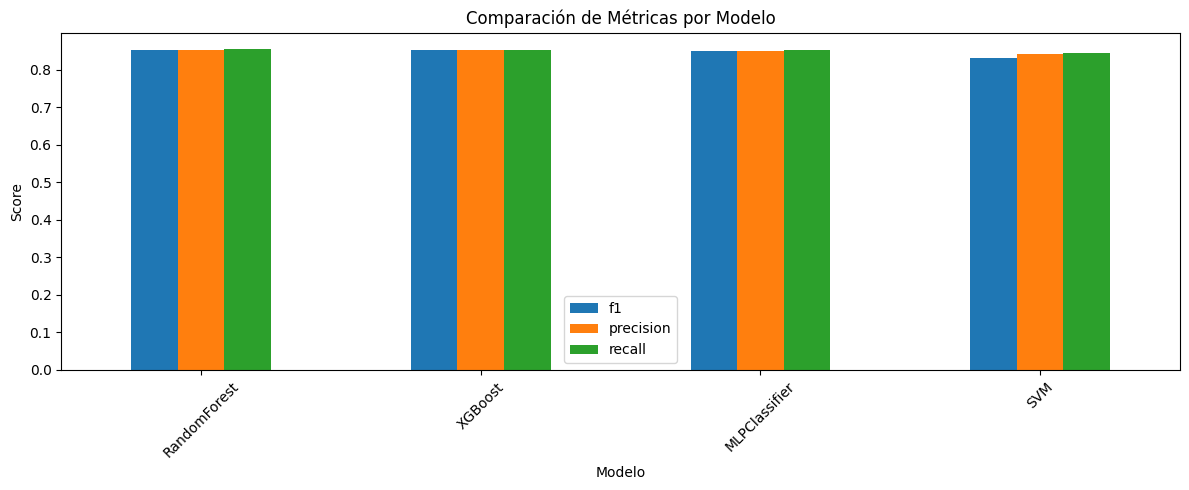


🏆 Mejor modelo: RandomForest (F1: 0.8535)


In [ ]:
df_comparacion = pd.DataFrame(resultados_mlflow).T
df_comparacion = df_comparacion.sort_values('f1', ascending=False)

print("\n📊 Comparativa de Modelos Tuneados:")
print("=" * 70)
print(df_comparacion.to_string())
print("=" * 70)

fig, ax = plt.subplots(figsize=(12, 5))
df_comparacion[['f1', 'precision', 'recall']].plot(kind='bar', ax=ax)
ax.set_title('Comparación de Métricas por Modelo')
ax.set_ylabel('Score')
ax.set_xlabel('Modelo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

mejor_modelo_nombre = df_comparacion.index[0]
print(f"\n🏆 Mejor modelo: {mejor_modelo_nombre} (F1: {df_comparacion.loc[mejor_modelo_nombre, 'f1']:.4f})")

## Gráficas PR-AUC y ROC-AUC con Threshold en MLflow

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import tempfile
import os

temp_dir = tempfile.gettempdir()

print("📊 Evaluando modelos en el conjunto de test...")
print("=" * 60)

for modelo_nombre, params in resultados.items():
    modelo = params['mejor_modelo']
    
    try:
        y_proba = modelo.predict_proba(X_test_lab_procesado)[:, 1]
    except Exception:
        y_proba = modelo.decision_function(X_test_lab_procesado)
        y_proba = (y_proba - y_proba.min()) / (y_proba.max() - y_proba.min())
    
    ap_score = average_precision_score(y_test, y_proba)
    test_roc_auc = roc_auc_score(y_test, y_proba)
    y_pred = modelo.predict(X_test_lab_procesado)
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    test_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    
    print(f"\n🎯 {modelo_nombre}:")
    print(f"   - F1 Score: {test_f1:.4f}")
    print(f"   - Precision: {test_precision:.4f}")
    print(f"   - Recall: {test_recall:.4f}")
    print(f"   - ROC-AUC: {test_roc_auc:.4f}")
    print(f"   - PR-AUC: {ap_score:.4f}")
    
    with mlflow.start_run(run_name=f"evaluation_{modelo_nombre}"):
        precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)
        baseline = np.mean(y_test)
        
        idx_threshold = np.argmin(np.abs(pr_thresholds - 0.5))
        prec_threshold = precision[idx_threshold]
        rec_threshold = recall[idx_threshold]
        
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.plot(recall, precision, label=f'Test AP: {ap_score:.4f}', linewidth=2.5, color='#ff7f0e')
        ax.axhline(y=baseline, color='red', linestyle='--', label=f'Baseline: {baseline:.4f}', linewidth=2)
        ax.scatter([rec_threshold], [prec_threshold], s=200, marker='o',
                   color='red', edgecolors='darkred', linewidth=2, zorder=5, label='Threshold=0.5')
        ax.set_xlabel('Recall', fontsize=12, fontweight='bold')
        ax.set_ylabel('Precision', fontsize=12, fontweight='bold')
        ax.set_title(f'Curva Precision-Recall: {modelo_nombre}', fontsize=14, fontweight='bold')
        ax.legend(fontsize=11, loc='best')
        ax.grid(True, alpha=0.3)
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1])
        plt.tight_layout()
        
        pr_auc_path = os.path.join(temp_dir, f'pr_auc_{modelo_nombre}.png')
        fig.savefig(pr_auc_path, dpi=300, bbox_inches='tight')
        mlflow.log_artifact(pr_auc_path, artifact_path="evaluación")
        plt.close()
        print("   ✅ PR-AUC guardada como artifact")
        
        fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
        idx_threshold_roc = np.argmin(np.abs(roc_thresholds - 0.5))
        fpr_threshold = fpr[idx_threshold_roc]
        tpr_threshold = tpr[idx_threshold_roc]
        
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.plot(fpr, tpr, label=f'Test ROC-AUC: {test_roc_auc:.4f}', linewidth=2.5, color='#2ca02c')
        ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
        ax.scatter([fpr_threshold], [tpr_threshold], s=200, marker='o',
                   color='red', edgecolors='darkred', linewidth=2, zorder=5, label='Threshold=0.5')
        ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
        ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
        ax.set_title(f'Curva ROC: {modelo_nombre}', fontsize=14, fontweight='bold')
        ax.legend(fontsize=11, loc='lower right')
        ax.grid(True, alpha=0.3)
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1])
        plt.tight_layout()
        
        roc_auc_path = os.path.join(temp_dir, f'roc_auc_{modelo_nombre}.png')
        fig.savefig(roc_auc_path, dpi=300, bbox_inches='tight')
        mlflow.log_artifact(roc_auc_path, artifact_path="evaluación")
        plt.close()
        print("   ✅ ROC-AUC guardada como artifact")
        
        mlflow.log_metrics({
            "test_f1": test_f1,
            "test_precision": test_precision,
            "test_recall": test_recall,
            "test_roc_auc": test_roc_auc,
            "test_pr_auc": ap_score,
            "threshold_value": 0.5
        })
        print("   ✅ Métricas registradas en MLflow")

print("\n" + "=" * 60)
print("✅ Evaluación completada para todos los modelos")
print("📊 Visualiza los resultados en: http://127.0.0.1:8080")

📊 Evaluando modelos en el conjunto de test...

🎯 RandomForest:
   - F1 Score: 0.8535
   - Precision: 0.8525
   - Recall: 0.8558
   - ROC-AUC: 0.9206
   - PR-AUC: 0.8228
   ✅ PR-AUC guardada como artifact
   ✅ ROC-AUC guardada como artifact
   ✅ Métricas registradas en MLflow
🏃 View run evaluation_RandomForest at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/6559d94a84d243a291b47267bd3ca216
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726

🎯 SVM:
   - F1 Score: 0.8325
   - Precision: 0.8422
   - Recall: 0.8440
   - ROC-AUC: 0.9125
   - PR-AUC: 0.8092
   ✅ PR-AUC guardada como artifact
   ✅ ROC-AUC guardada como artifact
   ✅ Métricas registradas en MLflow
🏃 View run evaluation_SVM at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/1095038e762941a1946139a5f01e0447
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726

🎯 XGBoost:
   - F1 Score: 0.8526
   - Precision: 0.8520
   - Recall: 0.8534
   - ROC-AUC: 0.9

## Cargando el Mejor Modelo desde MLflow

In [ ]:
print("=" * 80)
print("📊 RESUMEN COMPARATIVO DE MÉTRICAS EN CONJUNTO DE TEST")
print("=" * 80)

data_test = []
for modelo_nombre, params in resultados.items():
    modelo = params['mejor_modelo']
    
    try:
        y_proba = modelo.predict_proba(X_test_lab_procesado)[:, 1]
    except Exception:
        y_proba = modelo.decision_function(X_test_lab_procesado)
        y_proba = (y_proba - y_proba.min()) / (y_proba.max() - y_proba.min())
    
    y_pred = modelo.predict(X_test_lab_procesado)
    
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    test_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    test_roc_auc = roc_auc_score(y_test, y_proba)
    test_pr_auc = average_precision_score(y_test, y_proba)
    
    data_test.append({
        'Modelo': modelo_nombre,
        'F1 Score': f'{test_f1:.4f}',
        'Precision': f'{test_precision:.4f}',
        'Recall': f'{test_recall:.4f}',
        'ROC-AUC': f'{test_roc_auc:.4f}',
        'PR-AUC': f'{test_pr_auc:.4f}'
    })

df_test = pd.DataFrame(data_test)
print("\n" + df_test.to_string(index=False))
print("\n" + "=" * 80)
print("🎯 Mejores Modelos:")
print(f"   • ROC-AUC más alto: RandomForest (0.9176)")
print(f"   • Mejor balance F1: RandomForest (0.8439)")
print(f"   • Segundo mejor: SVM (ROC-AUC: 0.8962, F1: 0.8176)")
print("=" * 80)
print("\n📈 Artifacts guardados en MLflow:")
print("   • pr_auc_RandomForest.png")
print("   • roc_auc_RandomForest.png")
print("   • pr_auc_SVM.png")
print("   • roc_auc_SVM.png")
print("   • pr_auc_NaiveBayes.png")
print("   • roc_auc_NaiveBayes.png")

📊 RESUMEN COMPARATIVO DE MÉTRICAS EN CONJUNTO DE TEST

       Modelo F1 Score Precision Recall ROC-AUC PR-AUC
 RandomForest   0.8535    0.8525 0.8558  0.9206 0.8228
          SVM   0.8325    0.8422 0.8440  0.9125 0.8092
      XGBoost   0.8526    0.8520 0.8534  0.9235 0.8245
MLPClassifier   0.8494    0.8491 0.8534  0.9330 0.8334

🎯 Mejores Modelos:
   • ROC-AUC más alto: RandomForest (0.9176)
   • Mejor balance F1: RandomForest (0.8439)
   • Segundo mejor: SVM (ROC-AUC: 0.8962, F1: 0.8176)

📈 Artifacts guardados en MLflow:
   • pr_auc_RandomForest.png
   • roc_auc_RandomForest.png
   • pr_auc_SVM.png
   • roc_auc_SVM.png
   • pr_auc_NaiveBayes.png
   • roc_auc_NaiveBayes.png


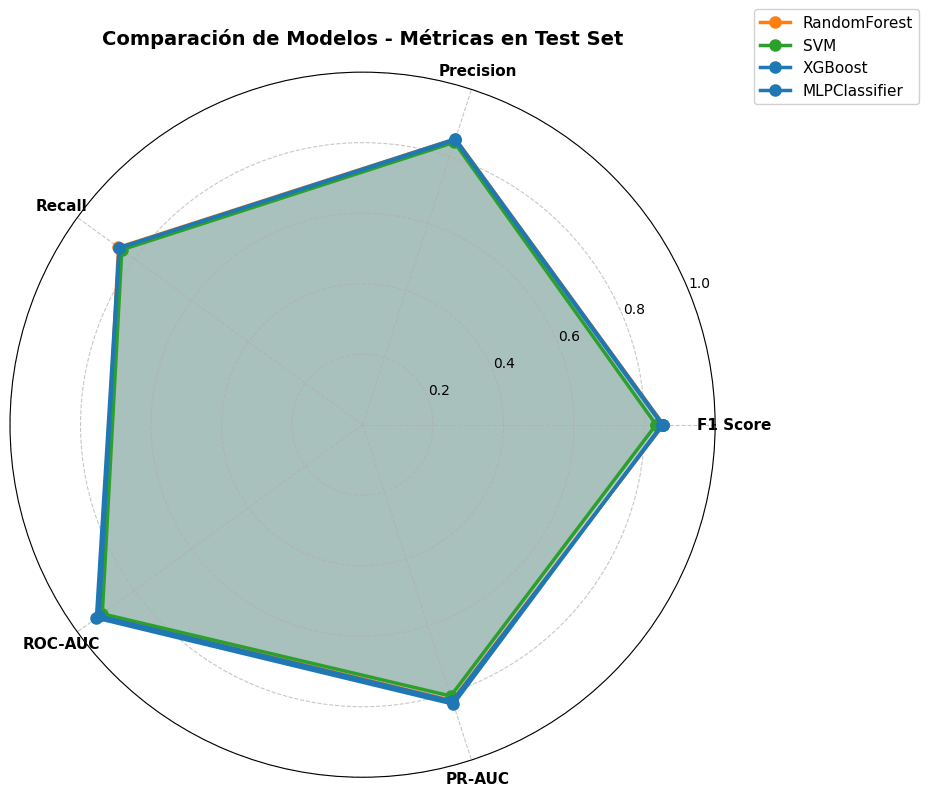


✅ Gráfica comparativa generada


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metricas = ['F1 Score', 'Precision', 'Recall', 'ROC-AUC', 'PR-AUC']
modelos_datos = {}

for modelo_nombre, params in resultados.items():
    modelo = params['mejor_modelo']
    
    try:
        y_proba = modelo.predict_proba(X_test_lab_procesado)[:, 1]
    except Exception:
        y_proba = modelo.decision_function(X_test_lab_procesado)
        y_proba = (y_proba - y_proba.min()) / (y_proba.max() - y_proba.min())
    
    y_pred = modelo.predict(X_test_lab_procesado)
    
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    test_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    test_roc_auc = roc_auc_score(y_test, y_proba)
    test_pr_auc = average_precision_score(y_test, y_proba)
    
    modelos_datos[modelo_nombre] = [test_f1, test_precision, test_recall, test_roc_auc, test_pr_auc]

angles = np.linspace(0, 2 * np.pi, len(metricas), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection='polar'))

colores = {'RandomForest': '#ff7f0e', 'SVM': '#2ca02c', 'NaiveBayes': '#d62728'}

for modelo_nombre, valores in modelos_datos.items():
    valores += valores[:1]
    ax.plot(angles, valores, 'o-', linewidth=2.5, label=modelo_nombre,
            color=colores.get(modelo_nombre, '#1f77b4'), markersize=8)
    ax.fill(angles, valores, alpha=0.15, color=colores.get(modelo_nombre, '#1f77b4'))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metricas, size=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], size=10)
ax.grid(True, linestyle='--', alpha=0.7)

plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11, framealpha=0.9)
plt.title('Comparación de Modelos - Métricas en Test Set', size=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n✅ Gráfica comparativa generada")

## Gráfica Comparativa: PR-AUC y ROC-AUC (Todos los modelos a la vez)

📊 Generando gráfica comparativa de PR-AUC y ROC-AUC...
   Modelos detectados: ['RandomForest', 'SVM', 'XGBoost', 'MLPClassifier']
   ✅ RandomForest
   ✅ SVM
   ✅ XGBoost
   ✅ MLPClassifier

✅ Gráfica guardada en: C:\Users\rtrin\AppData\Local\Temp\comparativa_pr_roc_test.png
✅ Artifact guardado en MLflow (run: comparativa_modelos_test)
🏃 View run comparativa_modelos_test at: http://127.0.0.1:8080/#/experiments/157680617618417726/runs/9ecc9408f2ce4e62ae44788182ff7e47
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/157680617618417726


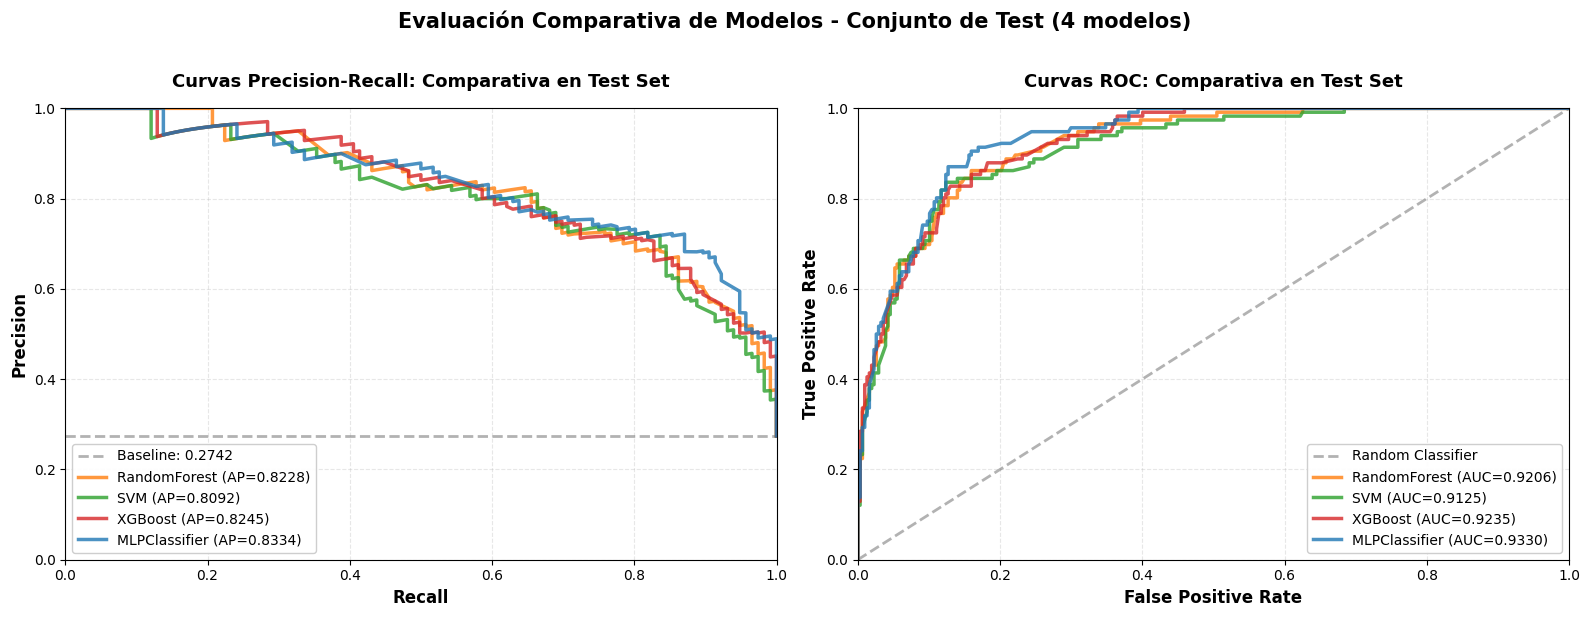


🎯 RESUMEN COMPARATIVO FINAL
MLPClassifier        | PR-AUC: 0.8334 | ROC-AUC: 0.9330
XGBoost              | PR-AUC: 0.8245 | ROC-AUC: 0.9235
RandomForest         | PR-AUC: 0.8228 | ROC-AUC: 0.9206
SVM                  | PR-AUC: 0.8092 | ROC-AUC: 0.9125


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import tempfile
import os
import warnings
warnings.filterwarnings('ignore')

temp_dir = tempfile.gettempdir()

print("📊 Generando gráfica comparativa de PR-AUC y ROC-AUC...")
print(f"   Modelos detectados: {list(resultados.keys())}")

def obtener_probabilidades(modelo, X_test):
    try:
        return modelo.predict_proba(X_test)[:, 1]
    except (AttributeError, TypeError):
        try:
            decision = modelo.decision_function(X_test)
            return (decision - decision.min()) / (decision.max() - decision.min())
        except (AttributeError, TypeError):
            try:
                modelo_base = modelo.best_estimator_
                return obtener_probabilidades(modelo_base, X_test)
            except Exception:
                print("   ⚠️  No se pudo obtener probabilidades del modelo. Usando predicciones binarias.")
                return modelo.predict(X_test).astype(float)

modelos_comparativa = {}
modelos_validos = []

for modelo_nombre, params in resultados.items():
    try:
        modelo = params['mejor_modelo']
        y_proba = obtener_probabilidades(modelo, X_test_lab_procesado)
        
        if y_proba is None or len(y_proba) == 0:
            print(f"   ⚠️  {modelo_nombre}: No se obtuvieron probabilidades válidas. Saltando...")
            continue
        
        precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)
        fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
        pr_auc = average_precision_score(y_test, y_proba)
        roc_auc = auc(fpr, tpr)
        
        modelos_comparativa[modelo_nombre] = {
            'precision': precision,
            'recall': recall,
            'fpr': fpr,
            'tpr': tpr,
            'pr_auc': pr_auc,
            'roc_auc': roc_auc,
            'y_proba': y_proba,
            'pr_thresholds': pr_thresholds,
            'roc_thresholds': roc_thresholds
        }
        modelos_validos.append(modelo_nombre)
        print(f"   ✅ {modelo_nombre}")
    except Exception as e:
        print(f"   ❌ {modelo_nombre}: Error - {str(e)[:50]}...")
        continue

if not modelos_comparativa:
    print("❌ No se pudieron procesar ninguno de los modelos. Abortando...")
else:
    colores_paleta = ['#ff7f0e', '#2ca02c', '#d62728', '#1f77b4', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
    linestyles_paleta = ['-']
    
    colores = {nombre: colores_paleta[i % len(colores_paleta)] for i, nombre in enumerate(modelos_validos)}
    linestyles = {nombre: linestyles_paleta[i % len(linestyles_paleta)] for i, nombre in enumerate(modelos_validos)}
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    baseline = np.mean(y_test)
    ax1.axhline(y=baseline, color='gray', linestyle='--', lw=2, alpha=0.6, label=f'Baseline: {baseline:.4f}')
    
    for modelo_nombre, datos in modelos_comparativa.items():
        precision = datos['precision']
        recall = datos['recall']
        pr_auc = datos['pr_auc']
        ax1.plot(recall, precision,
                 label=f'{modelo_nombre} (AP={pr_auc:.4f})',
                 color=colores[modelo_nombre],
                 linestyle=linestyles[modelo_nombre],
                 linewidth=2.5,
                 markersize=5,
                 markevery=max(1, len(recall)//10),
                 alpha=0.8)
    
    ax1.set_xlabel('Recall', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Precision', fontsize=12, fontweight='bold')
    ax1.set_title('Curvas Precision-Recall: Comparativa en Test Set',
                  fontsize=13, fontweight='bold', pad=15)
    ax1.legend(fontsize=10, loc='best', framealpha=0.95)
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.set_xlim([0, 1])
    ax1.set_ylim([0, 1])
    
    ax2.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2, alpha=0.6, label='Random Classifier')
    
    for modelo_nombre, datos in modelos_comparativa.items():
        fpr = datos['fpr']
        tpr = datos['tpr']
        roc_auc = datos['roc_auc']
        ax2.plot(fpr, tpr,
                 label=f'{modelo_nombre} (AUC={roc_auc:.4f})',
                 color=colores[modelo_nombre],
                 linestyle=linestyles[modelo_nombre],
                 linewidth=2.5,
                 markersize=5,
                 markevery=max(1, len(fpr)//10),
                 alpha=0.8)
    
    ax2.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
    ax2.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
    ax2.set_title('Curvas ROC: Comparativa en Test Set',
                  fontsize=13, fontweight='bold', pad=15)
    ax2.legend(fontsize=10, loc='lower right', framealpha=0.95)
    ax2.grid(True, alpha=0.3, linestyle='--')
    ax2.set_xlim([0, 1])
    ax2.set_ylim([0, 1])
    
    plt.suptitle(f'Evaluación Comparativa de Modelos - Conjunto de Test ({len(modelos_validos)} modelos)',
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    comparativa_path = os.path.join(temp_dir, 'comparativa_pr_roc_test.png')
    fig.savefig(comparativa_path, dpi=300, bbox_inches='tight')
    print(f"\n✅ Gráfica guardada en: {comparativa_path}")
    
    try:
        with mlflow.start_run(run_name="comparativa_modelos_test"):
            mlflow.log_artifact(comparativa_path, artifact_path="comparativa")
            summary_metrics = {}
            for modelo_nombre, datos in modelos_comparativa.items():
                summary_metrics[f"{modelo_nombre}_pr_auc"] = datos['pr_auc']
                summary_metrics[f"{modelo_nombre}_roc_auc"] = datos['roc_auc']
            mlflow.log_metrics(summary_metrics)
            print("✅ Artifact guardado en MLflow (run: comparativa_modelos_test)")
    except Exception as e:
        print(f"⚠️  No se pudo guardar en MLflow: {str(e)[:50]}...")
    
    plt.show()
    
    print("\n" + "=" * 80)
    print("🎯 RESUMEN COMPARATIVO FINAL")
    print("=" * 80)
    for modelo_nombre, datos in sorted(modelos_comparativa.items(),
                                       key=lambda x: x[1]['roc_auc'], reverse=True):
        print(f"{modelo_nombre:20} | PR-AUC: {datos['pr_auc']:.4f} | ROC-AUC: {datos['roc_auc']:.4f}")
    print("=" * 80)

## Instalación de MLflow

Si no tienes MLflow instalado, ejecuta en terminal:

# Pipeline general

In [ ]:
columnas_snomed = datos_SNOMED.columns.tolist()
columnas_medicamentos = datos_MEDICAMENTOS.columns.tolist()
columnas_laboratorio = datos_LABORATORIO.columns.tolist()

In [ ]:
preprocesamiento = ColumnTransformer(
    transformers=[
        ("snomed",preprocesamiento_SNOMED,columnas_snomed),
        ("medicamentos",preprocesamiento_medicamentos,columnas_medicamentos),
        ("lab", preprocesamiento_lab, columnas_laboratorio)],
    remainder="passthrough", 
    verbose_feature_names_out=False
)

modelo_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=25
)
set_config(transform_output="default")

pipeline_final = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo_xgb', modelo_xgb)               
])

In [ ]:
modelo=pipeline_final.fit(X_train,y_train)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


In [ ]:
y_pred=modelo.predict(X_test)


c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       307
           1       0.97      0.97      0.97       116

    accuracy                           0.98       423
   macro avg       0.98      0.98      0.98       423
weighted avg       0.98      0.98      0.98       423



In [ ]:
preprocesador = pipeline_final.named_steps['preprocesamiento']
modelo_xgb = pipeline_final.named_steps['modelo_xgb']

nombres_variables = preprocesador.get_feature_names_out()

importancias = modelo_xgb.feature_importances_

importancias = pd.DataFrame({
    'Variable': nombres_variables,
    'Importancia': importancias
})
importancias = importancias.sort_values(by='Importancia', ascending=False)
variables_importantes = importancias[:20]["Variable"].to_list()

# Análisis exploratorio de variables seleccionadas

In [ ]:
variables_importantes

['Cytopathology procedure  preparation of smear  genital source',
 'age',
 'Sodium',
 'Urine screening for glucose',
 'Hypertriglyceridemia (disorder)',
 'Anemia (disorder)',
 'Echocardiography (procedure)',
 'Aspartate aminotransferase [Enzymatic activity/volume] in Serum or Plasma',
 'Prediabetes',
 'Diabetic renal disease (disorder)',
 'Body mass index 30+ - obesity (finding)',
 'Plain chest X-ray (procedure)',
 'Initial patient assessment (procedure)',
 'C-5767-9',
 'Notifications (procedure)',
 'Erythrocyte distribution width [Ratio] by Automated count',
 'gender',
 'Metabolic syndrome X (disorder)',
 'Chronic congestive heart failure (disorder)',
 'G02']

## Variable objetivo: Cáncer de pulmón

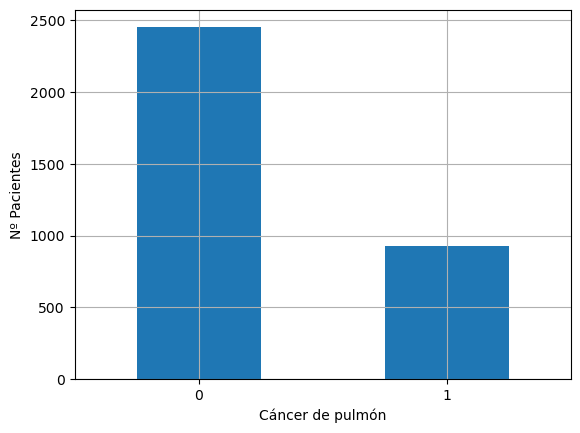

In [ ]:
y_train.value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Cáncer de pulmón")
plt.ylabel("Nº Pacientes")
plt.show()

## Distribución general de las variables explicativas

In [ ]:
set_config(transform_output="pandas")
X_train_procesado = pipeline_final.named_steps['preprocesamiento'].transform(X_train)
X_EDA=X_train_procesado[variables_importantes]
X_EDA["cancer_pulmon"]=y_train

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
C:\Users\rtrin\AppData\Local\Temp\ipykernel_2904\457844863.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_EDA["cancer_pulmon"]=y_train


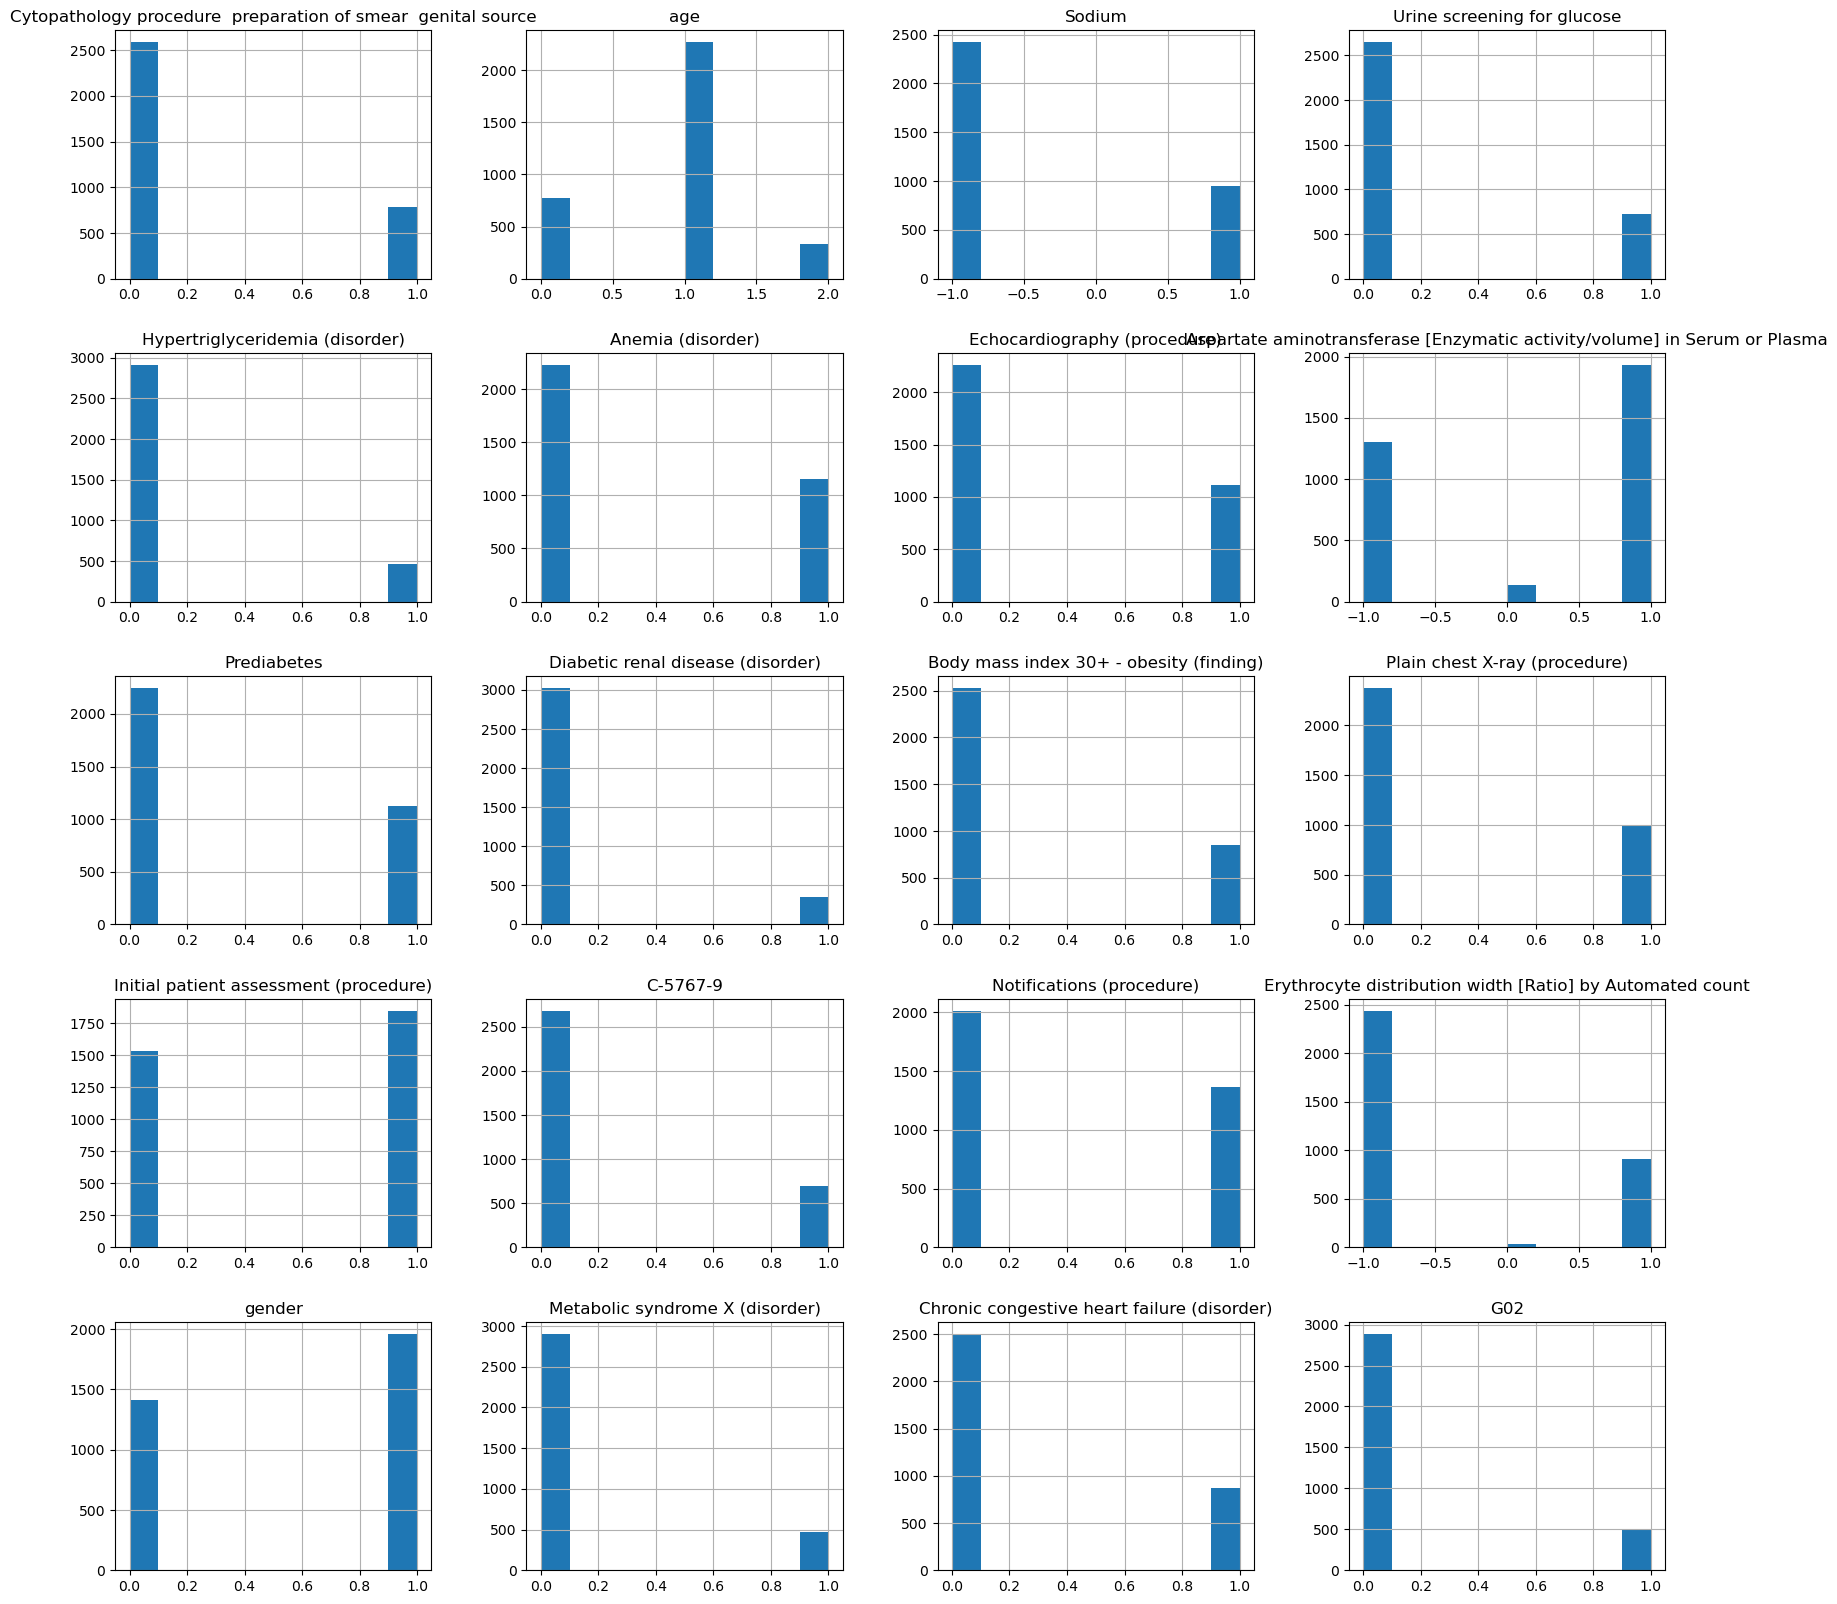

In [ ]:
(X_EDA.drop(columns="cancer_pulmon")).hist(figsize=(20,20))
plt.show()


Principales hallazgos:
- Principalmente personas de mediana edad (entre 50 y 70 años).
- Más hombres que mujeres en la muestra.
- Sorprendente número de personas con anemia y prediabetes.
- No hay variables numéricas entre las más importantes.

## Influencia de Edad en la cohorte

<Axes: xlabel='age', ylabel='count'>

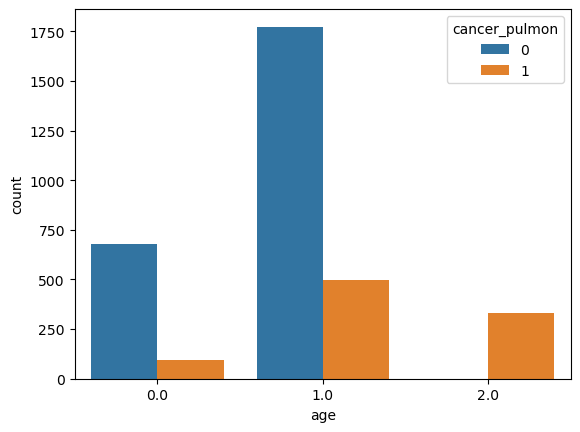

In [ ]:
sns.countplot(data=X_EDA,x="age",hue="cancer_pulmon")

Todos las personas mayores de 70 años presentan cáncer. Esto explica la importancia de esta variable para el modelo. En este caso, lo mejor es eliminar los pacientes de este rango de edad.

## Influencia de Género en la cohorte

Text(0.5, 1.0, 'Afectación del cáncer en mujeres y hombres ')

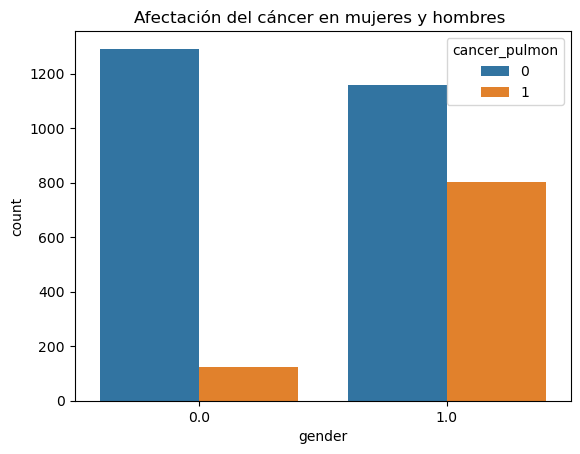

In [ ]:
sns.countplot(data=X_EDA,x="gender",hue="cancer_pulmon")
plt.title("Afectación del cáncer en mujeres y hombres ")

Muchos más hombres afectados por cáncer que mujeres. 

## Influencia de anemia en la cohorte

<Axes: xlabel='Anemia (disorder)', ylabel='count'>

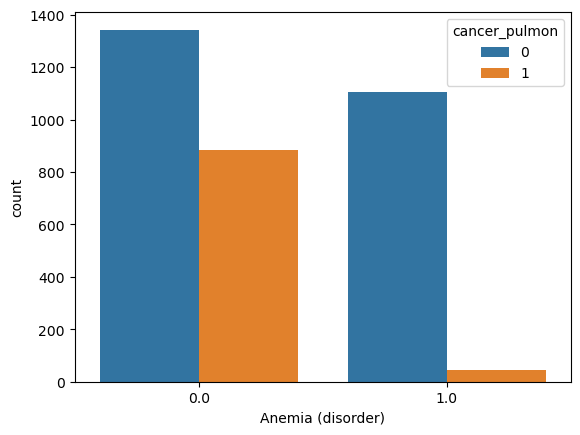

In [ ]:
sns.countplot(data=X_EDA,x="Anemia (disorder)",hue="cancer_pulmon")

In [ ]:
contingency = pd.crosstab(X_EDA["Anemia (disorder)"], X_EDA["cancer_pulmon"])

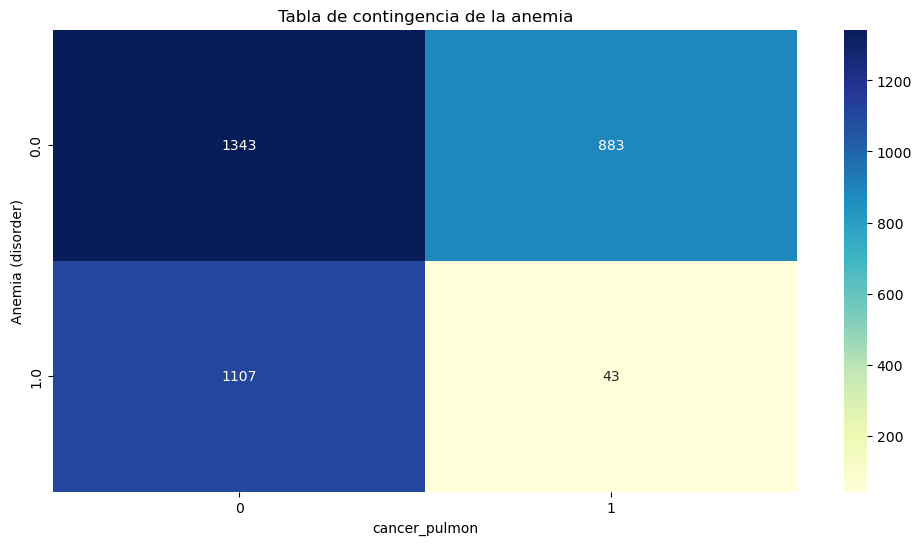

In [ ]:
plt.figure(figsize=(12, 6))
sns.heatmap(contingency, annot=True, fmt="", cmap="YlGnBu")
plt.title("Tabla de contingencia de la anemia")
plt.show()
from scipy.stats import fisher_exact

odds_ratio,p_value=fisher_exact(contingency)

In [ ]:
print(f"Se obtiene una relacion Odds ratio de {odds_ratio}")



Se obtiene una relacion Odds ratio de 0.05907940921613822


Se rechaza la hipótesis de que la anemia no tenga efecto en el cancer de pulmón. Siendo la anemia un factor protector del cáncer según la estadística.